<img src="https://www.javeriana.edu.co/recursosdb/20125/5571273/escudo-circular.png" alt="Escudo" style="float:left;width:70px;">

<div align="center">

# Pontificia Universidad Javeriana

## Facultad de Ingeniería

### Curso: Procesamiento de Lenguaje Natural

# TALLER-4 — Recuperación de Información aplicada a entrevistas y libros de la Comisión de la Verdad (CEV)

**Integrantes**: Erika Valeria Rivera Jiménez — Julián Guillermo Carrillo Meneses — Carlos Andrés Garnica Salazar — Oscar Andrés Prieto Moreno

**Septiembre de 2026**

---

</div>


# Sec 00 — Entorno, rutas y funciones de carga

Este bloque concentra al inicio del notebook:

1. Verificacion de dependencias (instalacion silenciosa solo si falta algo,
   pensado para la primera ejecucion en Google Colab).
2. **Todos los imports** de librerias usados por las secciones siguientes.
3. Semilla global (42) y estilo de las figuras matplotlib.
4. `buscar_raiz()`: localiza la raiz del proyecto TALLER-4 subiendo desde el
   directorio actual hasta encontrar la carpeta que contiene
   `data/corpus/segmentos_libros.jsonl`. Funciona local (kernel abierto desde
   `notebooks/`, desde la raiz o desde cualquier subcarpeta) y en Colab con la
   carpeta `TALLER-4` completa subida.
5. Funciones de carga reutilizables por las demas secciones:
   `cargar_lemas(corpus)`, `cargar_metadatos(corpus)` y `aplicar_parada(texto)`
   (parada EN CONSUMO, mismo criterio del experimento IR de la Fase 6).

**Como ejecutarlo**: localmente desde `TALLER-4/notebooks/` (o desde la raiz
del proyecto); en Google Colab subiendo la carpeta `TALLER-4` completa. Todas
las rutas se resuelven de forma relativa a la raiz detectada, nunca absolutas.

In [1]:
"""Instalacion de dependencias (solo necesaria la primera vez en Colab)."""
import importlib.util
import subprocess
import sys


def instalar_si_falta(paquetes: list[str]) -> None:
    """Instala paquetes pip que no esten disponibles, en silencio.

    Args:
        paquetes: Lista de paquetes a verificar e instalar.
    """
    faltantes = [p for p in paquetes if importlib.util.find_spec(p) is None]
    if not faltantes:
        print("Dependencias ya instaladas:", ", ".join(paquetes))
        return
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])


instalar_si_falta(
    ["pandas", "numpy", "scikit-learn", "matplotlib", "spacy"]
)

Instalando: scikit-learn



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: /home/carlos/venv/bin/python -m pip install --upgrade pip


In [2]:
"""Imports globales del notebook.

Se importan aqui una sola vez; las secciones posteriores los reutilizan sin
volver a importar. Varios se usan en secciones posteriores del notebook y no
en este archivo; por eso llevan `# noqa: F401` (ruff), igual que en el
TALLER-2.
"""
import importlib
import json
import os
import random
from collections import Counter  # noqa: F401  (seccion 02)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # noqa: F401  (secciones 01-03)
from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: F401

# Backend inline: las figuras (plt.show) quedan embebidas en el notebook.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass  # ejecucion como script: backend por defecto

In [3]:
"""Semilla global y estilo de figuras del notebook."""

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
print(f"Semilla fija: {SEMILLA}")

Semilla fija: 42


In [4]:
"""Localizacion de la raiz del proyecto y rutas relativas a ella."""


def buscar_raiz() -> Path:
    """Directorio raiz del proyecto TALLER-4 (portatil: cualquier maquina).

    Estrategia de resolucion:
    1. Se parte de `os.getcwd()` y se sube por los padres hasta encontrar un
       directorio que contenga `data/corpus/segmentos_libros.jsonl`.
    2. Respaldo Colab: si no se encontro (kernel en /content), se prueban las
       ubicaciones tipicas de la carpeta TALLER-4 subida.

    Returns:
        Ruta absoluta a la raiz del proyecto (contiene data/, config/, ...).
    """
    candidato = Path(os.getcwd()).resolve()
    while candidato != candidato.parent:
        if (candidato / "data" / "corpus" / "segmentos_libros.jsonl").exists():
            return candidato
        candidato = candidato.parent
    for respaldo in (Path("/content/TALLER-4"), Path("/content/drive/MyDrive/TALLER-4")):
        if (respaldo / "data" / "corpus" / "segmentos_libros.jsonl").exists():
            return respaldo
    raise FileNotFoundError(
        "No se encontro la raiz del proyecto: falta data/corpus/segmentos_libros.jsonl "
        "en el arbol de directorios (sube la carpeta TALLER-4 completa en Colab)."
    )


RUTA_RAIZ = buscar_raiz()
RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
RUTA_PREPROCESADO = RUTA_CORPUS / "preprocesado"
RUTA_CONFIG = RUTA_RAIZ / "config"
RUTA_SCRIPTS = RUTA_RAIZ / "scripts"
RUTA_EXPERIMENTOS = RUTA_RAIZ / "experimentos"
RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
RUTA_EDA_RESULTADOS = RUTA_RESULTADOS / "eda"
RUTA_IMAGENES = RUTA_RAIZ / "imagenes"

print(f"RUTA_RAIZ: {RUTA_RAIZ}")

RUTA_RAIZ: /home/carlos/Git/PLN/TALLER-4


In [5]:
"""Carga de lemas, metadatos y parada en consumo (criterio de la Fase 6).

La parada y las correcciones aplican el MISMO criterio que
`experimentos/experimento_1_tfidf_base.py` (parada en consumo sobre lemas:
spacy.lang.es.STOP_WORDS + config/stopwords_habla.txt + ruido tipografico de
config/tfidf_config.json, y correcciones de config/lemas_correcciones.json).
Para no duplicar esa logica, se importa el modulo del experimento con
importlib (sys.path hacia experimentos/) y se delega en sus funciones
`construir_parada()`, `cargar_correcciones()` y `limpiar_linea()`. La primera
importacion tarda ~2-3 s (spacy.lang.es); las siguientes usan la cache de
sys.modules.
"""
def cargar_lemas(corpus: str) -> list[str]:
    """Lee el archivo de lemas de un corpus (1 documento por linea).

    Args:
        corpus: "libros" (coleccion de segmentos) o "entrevistas" (queries).

    Returns:
        Lista de lineas de lemas, en el orden alineado con *_docs.json.
    """
    ruta = RUTA_PREPROCESADO / f"{corpus}_lemas.txt"
    return [linea.rstrip("\n") for linea in ruta.open(encoding="utf-8")]


def cargar_metadatos(corpus: str) -> list[dict]:
    """Lee los metadatos de un corpus desde su *_docs.json.

    Args:
        corpus: "libros" o "entrevistas".

    Returns:
        Lista de dicts de metadatos (mismo orden que el archivo de lemas).
    """
    ruta = RUTA_PREPROCESADO / f"{corpus}_docs.json"
    return json.loads(ruta.read_text(encoding="utf-8"))["docs"]


def cargar_modulo_ir():
    """Importa experimentos/experimento_1_tfidf_base.py como modulo.

    La primera llamada registra el modulo en sys.modules; las siguientes son
    O(1). El modulo no ejecuta nada al importarse (solo constantes y
    definiciones), de modo que las secciones 00-03 comparten una unica fuente
    de verdad para parada, correcciones y pipeline del experimento.

    Returns:
        Modulo `experimento_1_tfidf_base` (con sus funciones publicas).
    """
    if "experimento_1_tfidf_base" in sys.modules:
        return sys.modules["experimento_1_tfidf_base"]
    if str(RUTA_EXPERIMENTOS) not in sys.path:
        sys.path.insert(0, str(RUTA_EXPERIMENTOS))
    return importlib.import_module("experimento_1_tfidf_base")


def aplicar_parada(linea_lemas: str) -> str:
    """Aplica correcciones y parada en consumo a una linea de lemas.

    Delega en `limpiar_linea()` del experimento (ver su docstring): primero la
    correccion de lemas anomalos (62 mapas) y despues la parada efectiva
    (611 tokens = STOP_WORDS de spacy + 51 muletillas + 42 ruido tipografico).
    Con esto el notebook usa exactamente el mismo criterio que el modelo IR.

    Args:
        linea_lemas: linea de un archivo *_lemas.txt (lemas separados por
            espacio).

    Returns:
        Linea limpia con los lemas de contenido separados por espacio.
    """
    exp = cargar_modulo_ir()
    parada = exp.construir_parada(incluir_muletillas=True)
    correcciones = exp.cargar_correcciones()
    return exp.limpiar_linea(linea_lemas, parada, correcciones)

In [6]:
"""Verificacion rapida de carga: lineas por corpus y ejemplo de parada."""

for corpus in ("libros", "entrevistas"):
    lemas = cargar_lemas(corpus)
    metas = cargar_metadatos(corpus)
    print(
        f"{corpus:12s} | {len(lemas)} documentos | "
        f"{sum(len(linea.split()) for linea in lemas):,} lemas fase 4 | "
        f"metadatos alineados: {len(metas) == len(lemas)}"
    )

demo = "atreveir el él pues cion y violencia sexual"
print("ejemplo parada en consumo:")
print("  antes :", demo)
print("  despues:", aplicar_parada(demo))

libros       | 917 documentos | 970,283 lemas fase 4 | metadatos alineados: True


entrevistas  | 2486 documentos | 10,923,423 lemas fase 4 | metadatos alineados: True
ejemplo parada en consumo:
  antes : atreveir el él pues cion y violencia sexual


  despues: atreveir cion violencia sexual


# Sec 01 — El corpus: morfologia del documento y normalizacion

## 1. Que es un documento en cada corpus

**Libros** (Informe Final CEV, 10 tomos PDF, ~9.000 paginas): el documento es
el **segmento**, construido con la regla ADR-001:

- Limite de segmento = seccion del TOC de nivel 1-2 de cada tomo; el front y
  back matter (portadas, glosario, bibliografia) se descartan.
- **Fusion**: las secciones de menos de **300 palabras** se fusionan con la
  siguiente (o con la anterior si es la ultima), para evitar segmentos
  minusculos.
- **Techo**: las secciones de mas de **4.000 palabras** se parten en
  fragmentos de hasta ~3.500 palabras, cortando en limites de pagina.
- **Id**: `TOMO-p<pagina_inicio>-<titulo-slug>`
  (ej. `HALLAZGOS-p129-las-masacres`).
- Resultado: **917 segmentos / 2.271.493 palabras** (extraccion sin solapes,
  sin huecos y con cobertura de pagina del 100 %; mapeo TOC 91-100 % por tomo,
  verificado en `resultados/extraccion_libros_report.json`).

**Entrevistas** (CEV, archivo unico JSON): el documento es la
**transcripcion completa** de la entrevista (id = nombre del PDF original,
ej. `5eb4e7bfda6da3b502da3589.pdf`; hasta ~850.000 caracteres). Son 2.486
transcripciones de victimas, testigos y excombatientes, con las marcas de
sistema de la transcripcion (etiquetas de turno TEST/ENT, codigos de pagina,
anotaciones entre corchetes y tokens de anonimizacion).

La celda siguiente carga la tabla por tomo desde
`resultados/extraccion_libros_report.json` (reporte de la Fase 3).

In [7]:
"""Imports, rutas (respaldo standalone) y tabla por tomo de la Fase 3."""

import json

import pandas as pd

# Rutas de sec00. En el notebook ya estan definidas por sec00_setup y este
# bloque no las pisa; el respaldo solo aplica si se ejecuta la seccion como
# script standalone (misma convencion de autocontencion que el TALLER-2).
if "RUTA_RAIZ" not in globals():
    import os as _os
    from pathlib import Path as _Path

    _candidato = _Path(_os.getcwd()).resolve()
    while _candidato != _candidato.parent:
        if (_candidato / "data" / "corpus" / "segmentos_libros.jsonl").exists():
            break
        _candidato = _candidato.parent
    RUTA_RAIZ = _candidato
    RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
    RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
    RUTA_SCRIPTS = RUTA_RAIZ / "scripts"

RUTA_RAW = RUTA_RAIZ / "data" / "raw"

# Orden canonico de los 10 tomos (plan/PLAN.md, Fase 3).
ORDEN_TOMOS = (
    "HALLAZGOS",
    "CONVOCATORIA",
    "NARRATIVA",
    "SUFRIR",
    "TESTIMONIAL",
    "CUERPO",
    "NNA",
    "VIOLACIONES",
    "ETNICO",
    "FUERA",
)
reporte_extraccion = json.loads(
    (RUTA_RESULTADOS / "extraccion_libros_report.json").read_text(encoding="utf-8")
)

filas_tomos = []
for tomo in ORDEN_TOMOS:
    datos = reporte_extraccion["tomos"][tomo]
    filas_tomos.append(
        {
            "tomo": tomo,
            "segmentos": datos["n_segmentos"],
            "palabras": f"{datos['palabras_totales']:,}",
            "media_palabras": f"{datos['palabras_media']:,.0f}",
            "min_palabras": datos["palabras_min"],
            "max_palabras": datos["palabras_max"],
        }
    )
tabla_tomos = pd.DataFrame(filas_tomos)
print("Segmentos de libro por tomo (Fase 3, extraccion desde PDF):")
print(tabla_tomos.to_string(index=False))
n_segmentos_total = sum(
    reporte_extraccion["tomos"][tomo]["n_segmentos"] for tomo in ORDEN_TOMOS
)
print(
    f"TOTAL: {n_segmentos_total:,} segmentos | "
    f"entrevistas (coleccion de queries): 2.486 transcripciones completas"
)

Segmentos de libro por tomo (Fase 3, extraccion desde PDF):
        tomo  segmentos palabras media_palabras  min_palabras  max_palabras
   HALLAZGOS        146  309,169          2,118           350          3990
CONVOCATORIA         14   14,157          1,011           379          3633
   NARRATIVA        111  230,995          2,081           324          3986
      SUFRIR         68  161,620          2,377           409          3867
 TESTIMONIAL        104  271,338          2,609           303          3753
      CUERPO         84  188,189          2,240           323          3936
         NNA         55  140,301          2,551           463          3894
 VIOLACIONES        148  457,293          3,090           390          3500
      ETNICO         91  286,607          3,150           311          3491
       FUERA         96  211,824          2,206           408          3958
TOTAL: 917 segmentos | entrevistas (coleccion de queries): 2.486 transcripciones completas


In [8]:
"""Normalizacion de entrevistas: ejemplo real antes/despues (1 registro).

Se lee UN solo registro: la primera entrevista del archivo crudo (JSON array
de ~230 MB; se decodifica solo su primer elemento) y su version normalizada
(primera linea del JSONL). Ambos comparten id_doc.
"""


def decodificar_primer_registro_lista_json(ruta: str) -> dict:
    """Decodifica solo el primer elemento de un JSON array de gran tamano.

    Lee el archivo por fragmentos con crecimiento exponencial y usa
    `json.JSONDecoder.raw_decode`; el costo es O(tamano del primer registro)
    y no O(archivo completo): aqui el crudo pesa ~230 MB y solo interesa una
    entrevista de ejemplo.

    Args:
        ruta: Ruta al archivo JSON que contiene un array de objetos.

    Returns:
        Primer elemento del array (dict de la entrevista cruda).

    Raises:
        ValueError: si el archivo no contiene un primer registro completo.
    """
    decodificador = json.JSONDecoder()
    with open(ruta, encoding="utf-8") as fh:
        fragmento = ""
        tamano = 1_000_000
        while True:
            trozo = fh.read(tamano)
            if not trozo:
                raise ValueError(f"JSON sin primer registro completo: {ruta}")
            fragmento += trozo
            inicio = fragmento.find("[")
            if inicio >= 0:
                idx = inicio + 1
                while idx < len(fragmento) and fragmento[idx] in " \t\n\r":
                    idx += 1  # raw_decode no omite espacios en blanco
                try:
                    registro, _ = decodificador.raw_decode(fragmento, idx=idx)
                    return registro
                except json.JSONDecodeError:
                    pass
            tamano *= 2


ruta_json_crudo = RUTA_RAW / "entrevistas_all_2023-03-21_14-24_05.json"
ruta_normalizadas = RUTA_CORPUS / "entrevistas_normalizadas.jsonl"
if ruta_json_crudo.exists() and ruta_normalizadas.exists():
    registro_crudo = decodificar_primer_registro_lista_json(str(ruta_json_crudo))
    with ruta_normalizadas.open(encoding="utf-8") as fh:
        registro_normalizado = json.loads(fh.readline())
else:
    # Respaldo estatico del mismo ejemplo real (doc 5eb4e7bfda6da3b502da3589.pdf):
    # el JSON crudo (~230 MB) no se versiona en git, asi que en un entorno sin
    # data/raw la celda sigue siendo demostrativa.
    print(
        "[aviso] JSON crudo de entrevistas no disponible en este entorno; "
        "se muestra un respaldo estatico del ejemplo real (mismo id_doc)."
    )
    registro_crudo = {
        "id_doc": "5eb4e7bfda6da3b502da3589.pdf",
        "text": (
            "TEST: Bajo la apariencia de una democracia formal, en Colombia se "
            "vivia un regimen de terror: servicios de inteligencia estatales "
            "de la ORGANIZACION PUBLICA 1 ---- se entrelazaban con grupos "
            "paramilitares de extrema derecha."
        ),
    }
    registro_normalizado = {
        "id_doc": "5eb4e7bfda6da3b502da3589.pdf",
        "text_normalizado": (
            "Bajo la apariencia de una democracia formal, en Colombia se vivia "
            "un regimen de terror: servicios de inteligencia estatales de la "
            "organizacion_publica se entrelazaban con grupos paramilitares de "
            "extrema derecha."
        ),
    }

id_ejemplo = registro_crudo["id_doc"]
print(
    f"id_doc del ejemplo: {id_ejemplo} | crudo <-> normalizado alineados: "
    f"{registro_normalizado['id_doc'] == id_ejemplo}"
)

lineas_crudas = [linea for linea in registro_crudo["text"].split("\n") if linea.strip()]
print("\n--- ANTES (texto crudo: 3 lineas reales con marcas de sistema) ---")
for linea in lineas_crudas[:3]:
    print(repr(linea[:170]))
texto_normalizado = registro_normalizado["text_normalizado"]
print("\n--- DESPUES (texto normalizado, inicio real del mismo testimonio) ---")
print(texto_normalizado[:400])
print("...")

print("\n--- Un token de anonimizacion, antes y despues ---")
i = registro_crudo["text"].find("ORGANIZACI")
if i >= 0:
    print("crudo      : ...", " ".join(registro_crudo["text"][i - 120 : i + 60].split()), "...")
j = texto_normalizado.find("organizacion_publica")
if j >= 0:
    print("normalizado: ...", " ".join(texto_normalizado[j - 100 : j + 40].split()), "...")

id_doc del ejemplo: 5eb4e7bfda6da3b502da3589.pdf | crudo <-> normalizado alineados: True

--- ANTES (texto crudo: 3 lineas reales con marcas de sistema) ---
'001-VI-00008'
'TEST:\xa0 Bajo la apariencia de una democracia formal, en Colombia se vivía '
'un régimen de terror: servicios de inteligencia estatales \xa0[INTERRUP]'

--- DESPUES (texto normalizado, inicio real del mismo testimonio) ---
Bajo la apariencia de una democracia formal, en Colombia se vivía un régimen de terror: servicios de inteligencia estatales ¿Estamos hablando...? ¿A partir de qué época estamos hablando? Estamos hablando ya a partir de 1985. Entonces, te decía que servicios de inteligencia oficiales, estructuras de las fuerzas militares y de Policía y del organizacion_publica se entrelazaban con grupos paramilitar
...

--- Un token de anonimizacion, antes y despues ---
crudo      : ... . Entonces, te decía que servicios de inteligencia oficiales, estructuras de las fuerzas militares y de Policía y del ORGANIZACIÓ

In [9]:
"""Categorias de anonimizacion y volumenes globales de la normalizacion."""

inventario = json.loads(
    (RUTA_RESULTADOS / "preprocesado" / "inventario_patrones_entrevistas.json")
    .read_text(encoding="utf-8")
)
totales = inventario["totales"]
categorias = pd.DataFrame(
    [
        {"categoria": nombre, "ocurrencias": conteo}
        for nombre, conteo in sorted(
            totales["anonimizados"].items(), key=lambda par: -par[1]
        )
    ]
)
print("Tokens anonimizados mapeados a categorias canonicas (ADR-002):")
print(categorias.to_string(index=False))
n_variantes = sum(len(v) for v in totales["variantes_anonimizados"].values())
print(
    f"Total mapeado: {sum(totales['anonimizados'].values()):,} tokens "
    f"({n_variantes} variantes ortograficas distintas normalizadas)"
)
print(
    f"Chars: {totales['chars_antes']:,} -> {totales['chars_despues']:,} "
    f"({inventario['reduccion_pct']:.2f} %)"
)
print(
    f"Etiquetas de hablante eliminadas: {totales['n_hablantes_linea']:,} | "
    f"guiones: {totales['n_guiones']:,} | anotaciones entre corchetes: "
    f"{totales['n_brackets']:,}"
)

Tokens anonimizados mapeados a categorias canonicas (ADR-002):
            categoria  ocurrencias
             conocido        58525
              anonimo        43262
  organizacion_social        25336
                lugar        24226
             familiar        21428
 organizacion_publica        18878
institucion_educativa         5974
     partido_politico            1
Total mapeado: 197,630 tokens (420 variantes ortograficas distintas normalizadas)
Chars: 200,518,396 -> 188,838,879 (5.82 %)
Etiquetas de hablante eliminadas: 653,328 | guiones: 291,868 | anotaciones entre corchetes: 138,613


## 2. El pipeline de preprocesado (codigo esencial, sin ejecutar spaCy)

El preprocesado completo tiene dos partes (scripts/02_preprocesar.py):

1. **Normalizacion estructural** (regex, sin spaCy): elimina codigos de
   sistema (`001-VI-00008`, lineas `AUDIO`), etiquetas de hablante al inicio
   de linea, guiones largos y anotaciones entre corchetes (inventariadas por
   tipo: interrupciones, emociones, pausas, cortes...), y mapea los tokens de
   anonimizacion a 8 categorias canonicas en minusculas (ADR-002:
   `organizacion_publica`, `organizacion_social`, `lugar`, `familiar`,
   `conocido`, `institucion_educativa`, `partido_politico` y `anonimo`).
2. **Preprocesado linguistico** (spaCy `es_core_news_md`, CPU): tokeniza,
   pasa a minusculas y lematiza con un pipeline unico para libros y
   entrevistas; elimina stopwords de spaCy y las muletillas del habla
   (config/stopwords_habla.txt), conserva los anos 1900-2025 y las categorias
   canonicas como un solo token (ADR-003; `n_process=8`, ~4.1x vs 1 hilo).

**El corpus ya viene procesado** (data/corpus/preprocesado/: 917 + 2.486
documentos en `*_lemas.txt`/`*_tokens.txt` con sus `*_docs.json` alineados),
asi que el notebook NO vuelve a ejecutar spaCy. La celda siguiente importa el
script real y muestra su codigo esencial: aplica la parte 1 (regex) sobre las
3 lineas crudas del ejemplo y define (sin correrla) la parte 2.

In [10]:
"""Importa scripts/02_preprocesar.py y muestra/ejecuta su parte 1 (regex)."""
import importlib.util
import inspect
import sys

ruta_script_02 = RUTA_SCRIPTS / "02_preprocesar.py"
_espec = importlib.util.spec_from_file_location("preprocesar_02", ruta_script_02)
assert _espec is not None and _espec.loader is not None
modulo_preprocesar = importlib.util.module_from_spec(_espec)
sys.modules["preprocesar_02"] = modulo_preprocesar
_espec.loader.exec_module(modulo_preprocesar)

print("=== normalizar_texto_entrevista() (parte 1: cabecera) ===")
fuente = inspect.getsource(modulo_preprocesar.normalizar_texto_entrevista)
print("\n".join(fuente.splitlines()[:30]))
print("    ... (el cuerpo completo aplica las reglas del inventario de patrones)")

print("\n=== construir_nlp() (parte 2, spaCy: definicion, NO se ejecuta) ===")
print(inspect.getsource(modulo_preprocesar.construir_nlp))

print("\n=== Parte 1 aplicada a las 3 primeras lineas crudas del ejemplo ===")
texto_prueba = "\n".join(lineas_crudas[:3])
contadores = modulo_preprocesar._nuevos_contadores_normalizacion()
normalizado = modulo_preprocesar.normalizar_texto_entrevista(texto_prueba, contadores)
print("ANTES :", " | ".join(texto_prueba.splitlines())[:220])
print("DESPUES:", normalizado[:220])

=== normalizar_texto_entrevista() (parte 1: cabecera) ===
def normalizar_texto_entrevista(texto: str, contadores: dict[str, Any]) -> str:
    """Aplica la normalizacion estructural de ADR-002/seccion (c) a un texto.

    Secuencia: codigo lider -> lineas AUDIO -> codigos embebidos -> corchetes
    -> etiquetas de hablante (linea, linea sola, aisladas) -> anonimizados
    (especificos y generico) -> guiones -> colapso de espacios. NO aplica
    lowercase ni lematizacion (eso va en la parte 2).

    Args:
        texto: transcripcion cruda de una entrevista.
        contadores: dict mutado con las estadisticas de la normalizacion
            (totales y por documento; ver normalizar_entrevistas_corpus).

    Returns:
        Texto normalizado en una unica linea (flujo de turnos unido).
    """
    t = texto.replace("\r\n", "\n").replace("\r", "\n").replace("\xa0", " ")

    # (1) Codigo de sistema al inicio del documento.
    m = RE_CODIGO_LIDER.match(t)
    if m:
        contadores["n_co

## 3. Regeneracion opcional (solo si se quiere reconstruir el corpus)

Si alguien quisiera regenerar el corpus desde el material crudo, el camino
recomendado es el CLI del script de produccion (NO reejecutar spaCy dentro
del notebook):

```bash
# Parte 1 + parte 2, libros y entrevistas (todo el pipeline):
/home/carlos/venv/bin/python scripts/02_preprocesar.py
# Equivalente por partes:
/home/carlos/venv/bin/python scripts/02_preprocesar.py normalizar
/home/carlos/venv/bin/python scripts/02_preprocesar.py spacy --corpus libros
/home/carlos/venv/bin/python scripts/02_preprocesar.py spacy --corpus entrevistas
```

La celda siguiente define (con try/except) la instalacion de spaCy y del
modelo `es_core_news_md`, por si en Colab se quisiera activar la regeneracion
desde el propio notebook. El flag `REGENERAR_PREPROCESADO_SPACY` permanece en
False: el corpus ya procesado es la fuente de las secciones 02 y 03.

In [11]:
"""Rutina de instalacion de spaCy + modelo (solo si se activa el flag)."""
import subprocess

REGENERAR_PREPROCESADO_SPACY = False  # cambiar a True solo para regenerar


def instalar_spacy_con_modelo() -> None:
    """Instala spaCy y descarga es_core_news_md si no estan disponibles."""
    try:
        import spacy
    except ImportError:
        print("Instalando spaCy...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "spacy"])
    import spacy

    try:
        spacy.load("es_core_news_md")
        print("Modelo es_core_news_md disponible.")
    except OSError:
        print("Descargando es_core_news_md...")
        subprocess.check_call(
            [sys.executable, "-m", "spacy", "download", "es_core_news_md"]
        )


if REGENERAR_PREPROCESADO_SPACY:
    instalar_spacy_con_modelo()
else:
    print(
        "Regeneracion desactivada (flag en False). El corpus preprocesado ya "
        "existe en data/corpus/preprocesado/ y es el insumo de las secciones "
        "02 (EDA) y 03 (IR)."
    )

Regeneracion desactivada (flag en False). El corpus preprocesado ya existe en data/corpus/preprocesado/ y es el insumo de las secciones 02 (EDA) y 03 (IR).


# Sec 02 — EDA ligero en el notebook

El EDA completo (Fase 5) fue un script de produccion (scripts/03_eda.py) que
congelo la config del modelo; sus figuras pesadas (nubes, violines,
near-duplicates) viven en `imagenes/` y se EMBEBEN mas abajo como markdown
con rutas relativas al notebook (`../imagenes/eda_*.png`).

En esta seccion se ejecutan EN el notebook analisis ligeros sobre los mismos
insumos (lemas ya procesados), para que el lector pueda reproducir el
razonamiento sin depender de archivos intermedios:

1. Histograma del numero de lemas por documento, por corpus (con la cola de
   entrevistas recortada al p99, igual que el EDA).
2. Top-20 de unigramas por corpus con la parada EN CONSUMO de la Fase 6
   (mismo criterio del modelo IR: spacy STOP_WORDS + muletillas + ruido +
   62 correcciones).
3. Dos figuras adicionales desde CSVs baratos de resultados/eda/:
   longitudes por documento (lemas de contenido) y diversidad lexica (TTR
   muestreado y Yule K).
4. Embebido de las 14 figuras pesadas del EDA con su interpretacion y la
   tabla de metricas por fase de resultados/metricas.json.

In [12]:
"""Imports, rutas y helpers de sec00 (respaldo solo para standalone)."""
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "RUTA_RAIZ" not in globals():  # respaldo standalone (ver sec00_setup)
    import os as _os

    _candidato = Path(_os.getcwd()).resolve()
    while _candidato != _candidato.parent:
        if (_candidato / "data" / "corpus" / "segmentos_libros.jsonl").exists():
            break
        _candidato = _candidato.parent
    RUTA_RAIZ = _candidato
    RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
    RUTA_PREPROCESADO = RUTA_CORPUS / "preprocesado"
    RUTA_CONFIG = RUTA_RAIZ / "config"
    RUTA_EXPERIMENTOS = RUTA_RAIZ / "experimentos"
    RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
    RUTA_EDA_RESULTADOS = RUTA_RESULTADOS / "eda"

if "cargar_lemas" not in globals():  # respaldo standalone (igual logica)
    def cargar_lemas(corpus: str) -> list[str]:
        ruta = RUTA_PREPROCESADO / f"{corpus}_lemas.txt"
        return [linea.rstrip("\n") for linea in ruta.open(encoding="utf-8")]

if "aplicar_parada" not in globals():
    import importlib
    import sys as _sys

    def aplicar_parada(linea_lemas: str) -> str:
        if "experimento_1_tfidf_base" not in _sys.modules:
            _sys.path.insert(0, str(RUTA_EXPERIMENTOS))
            importlib.import_module("experimento_1_tfidf_base")
        exp = _sys.modules["experimento_1_tfidf_base"]
        parada = exp.construir_parada(incluir_muletillas=True)
        correcciones = exp.cargar_correcciones()
        return exp.limpiar_linea(linea_lemas, parada, correcciones)

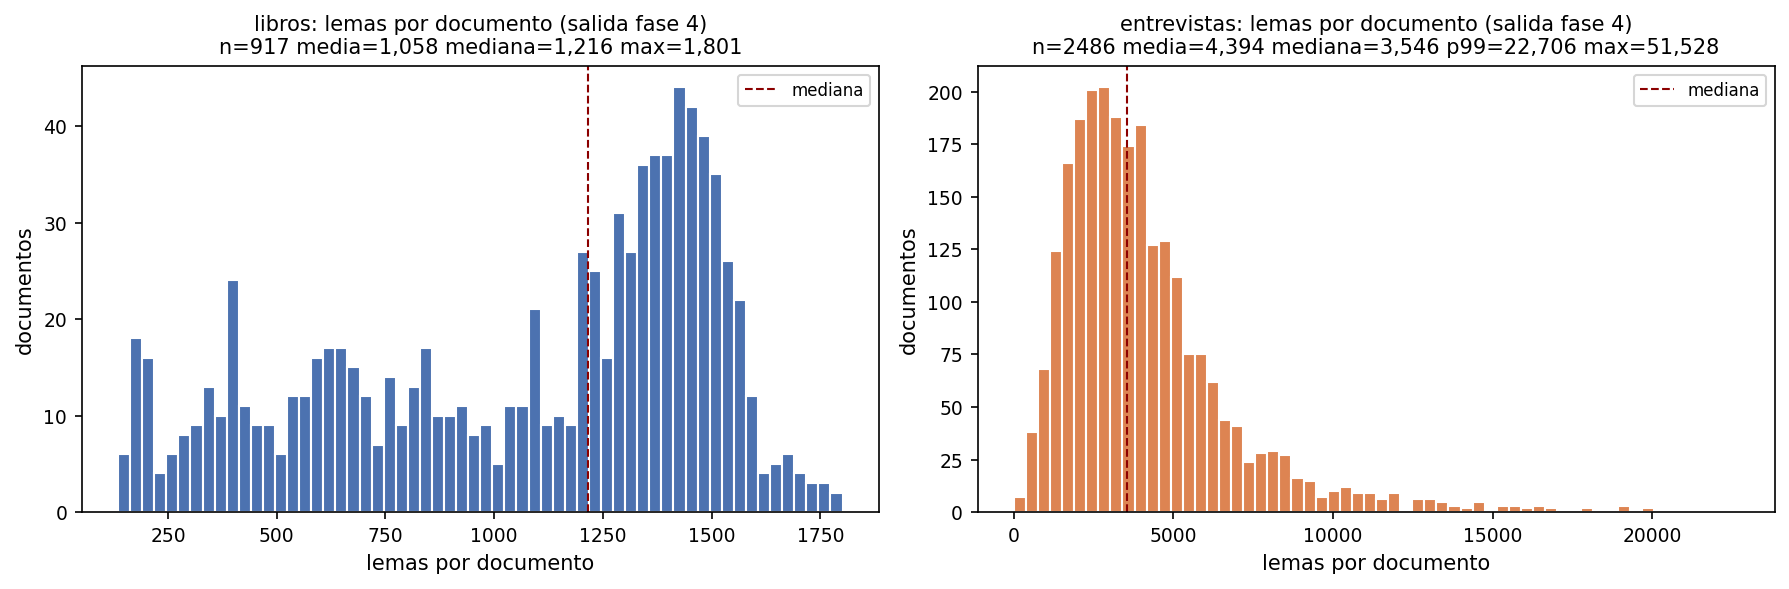

In [13]:
"""Histograma del numero de lemas por documento (por corpus)."""

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, corpus, color in zip(
    ejes, ("libros", "entrevistas"), ("#4C72B0", "#DD8452"), strict=True
):
    n_por_doc = [len(linea.split()) for linea in cargar_lemas(corpus)]
    valores = np.asarray(n_por_doc, dtype=float)
    recortar = corpus == "entrevistas"
    if recortar:
        corte = float(np.percentile(valores, 99))
        datos_hist = valores[valores <= corte]
        extra = f"p99={corte:,.0f} "
    else:
        datos_hist = valores
        extra = ""
    ax.hist(datos_hist, bins=60, color=color, edgecolor="white")
    ax.set_title(
        f"{corpus}: lemas por documento (salida fase 4)\n"
        f"n={len(valores)} media={valores.mean():,.0f} "
        f"mediana={np.median(valores):,.0f} {extra}max={valores.max():,.0f}",
        fontsize=10,
    )
    ax.set_xlabel("lemas por documento")
    ax.set_ylabel("documentos")
    ax.axvline(np.median(valores), color="darkred", ls="--", lw=1, label="mediana")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

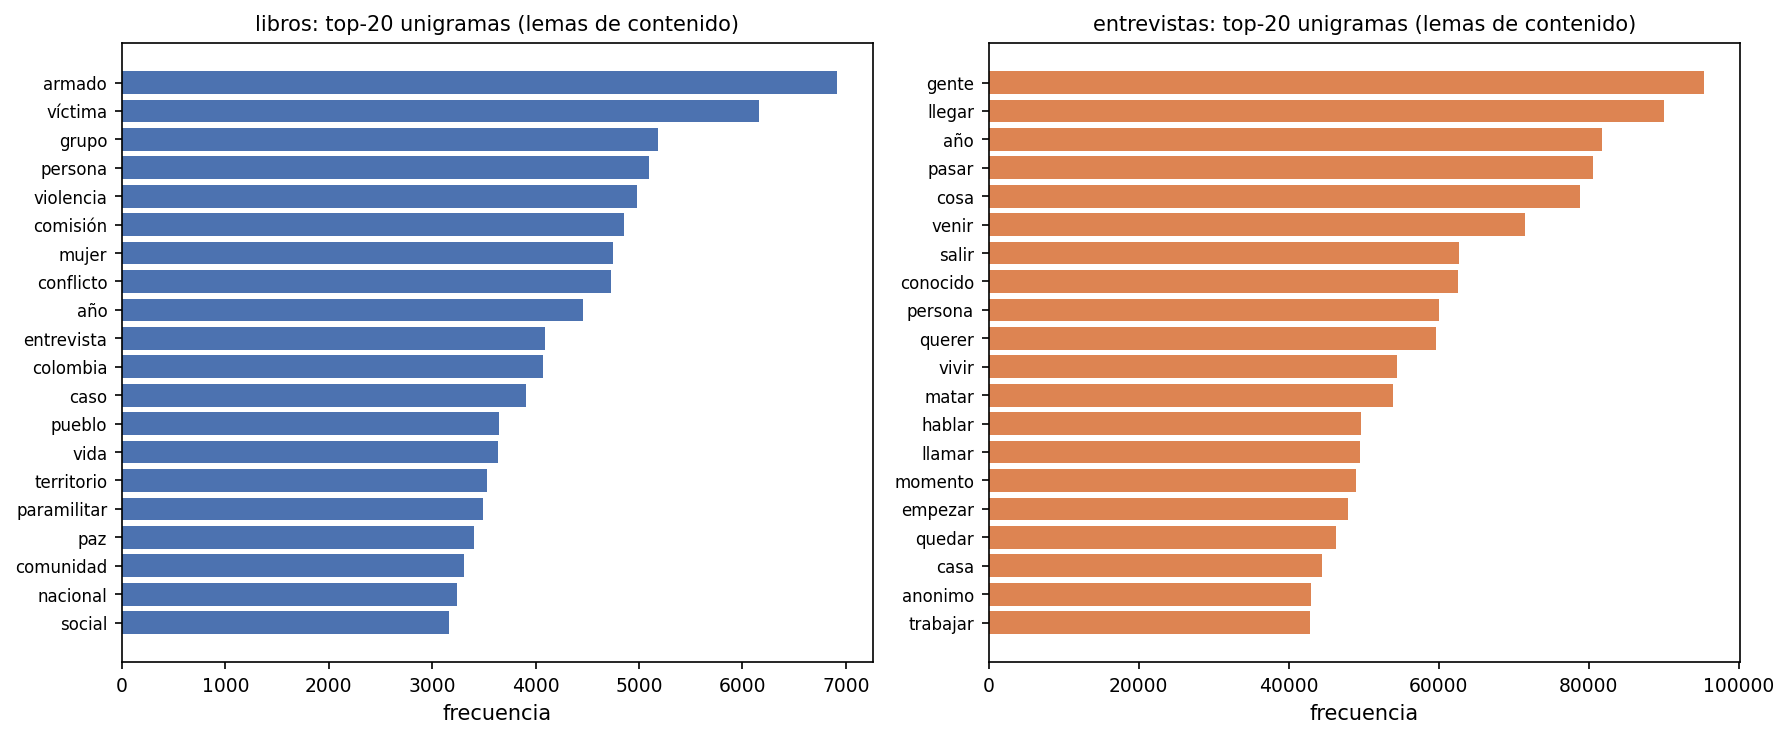

Top-10 libros      : armado víctima grupo persona violencia comisión mujer conflicto año entrevista


Top-10 entrevistas : gente llegar año pasar cosa venir salir conocido persona querer


In [14]:
"""Top-20 de unigramas por corpus (lemas de contenido, parada en consumo)."""

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for ax, corpus, color in zip(
    ejes, ("libros", "entrevistas"), ("#4C72B0", "#DD8452"), strict=True
):
    contador: Counter[str] = Counter()
    for linea in cargar_lemas(corpus):
        limpia = aplicar_parada(linea)
        if limpia:
            contador.update(limpia.split())
    top = contador.most_common(20)
    etiquetas = [t for t, _ in reversed(top)]
    valores = [c for _, c in reversed(top)]
    ax.barh(np.arange(len(valores)), valores, color=color)
    ax.set_yticks(np.arange(len(valores)), etiquetas, fontsize=8)
    ax.set_title(f"{corpus}: top-20 unigramas (lemas de contenido)", fontsize=10)
    ax.set_xlabel("frecuencia")
fig.tight_layout()
plt.show()

print("Top-10 libros      :", " ".join(t for t, _ in Counter(
    t
    for linea in cargar_lemas("libros")
    for t in aplicar_parada(linea).split()
).most_common(10)))
print("Top-10 entrevistas :", " ".join(t for t, _ in Counter(
    t
    for linea in cargar_lemas("entrevistas")
    for t in aplicar_parada(linea).split()
).most_common(10)))

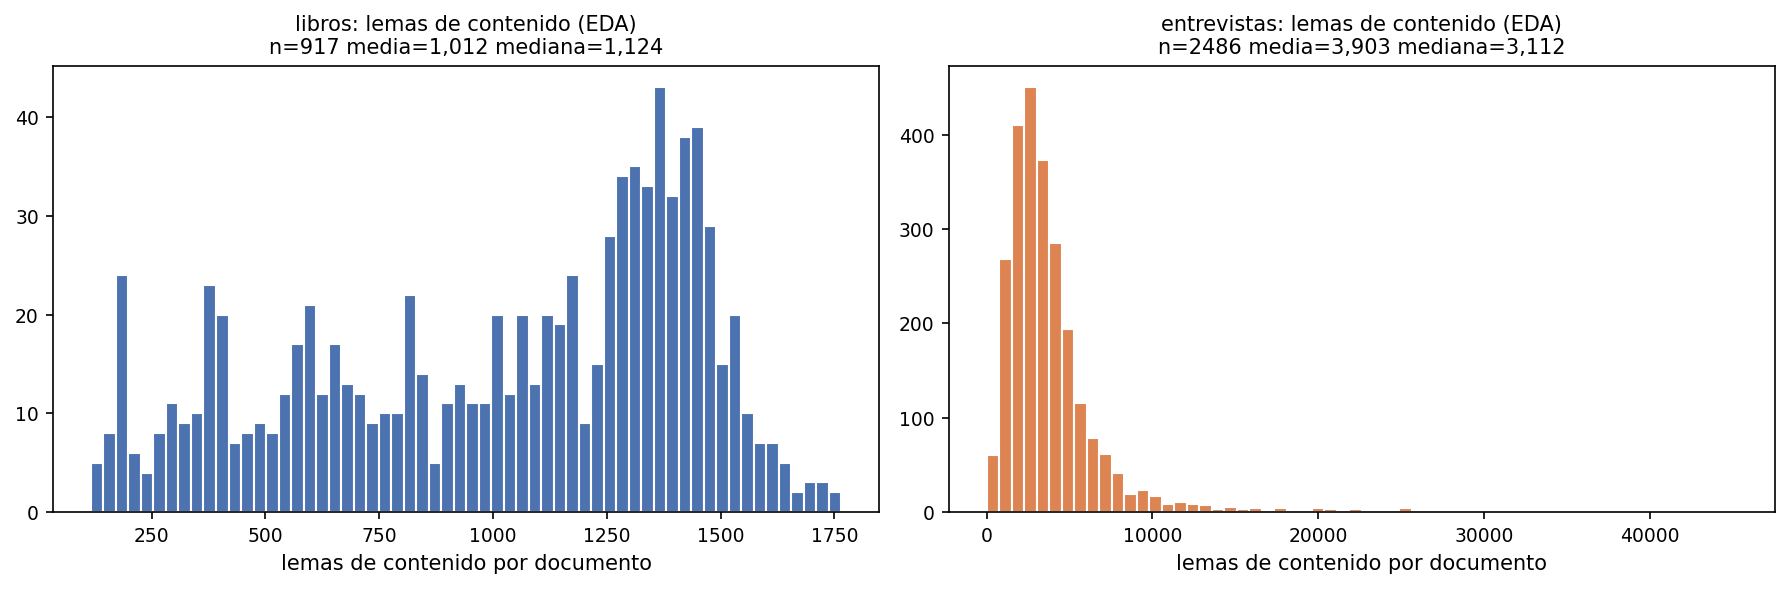

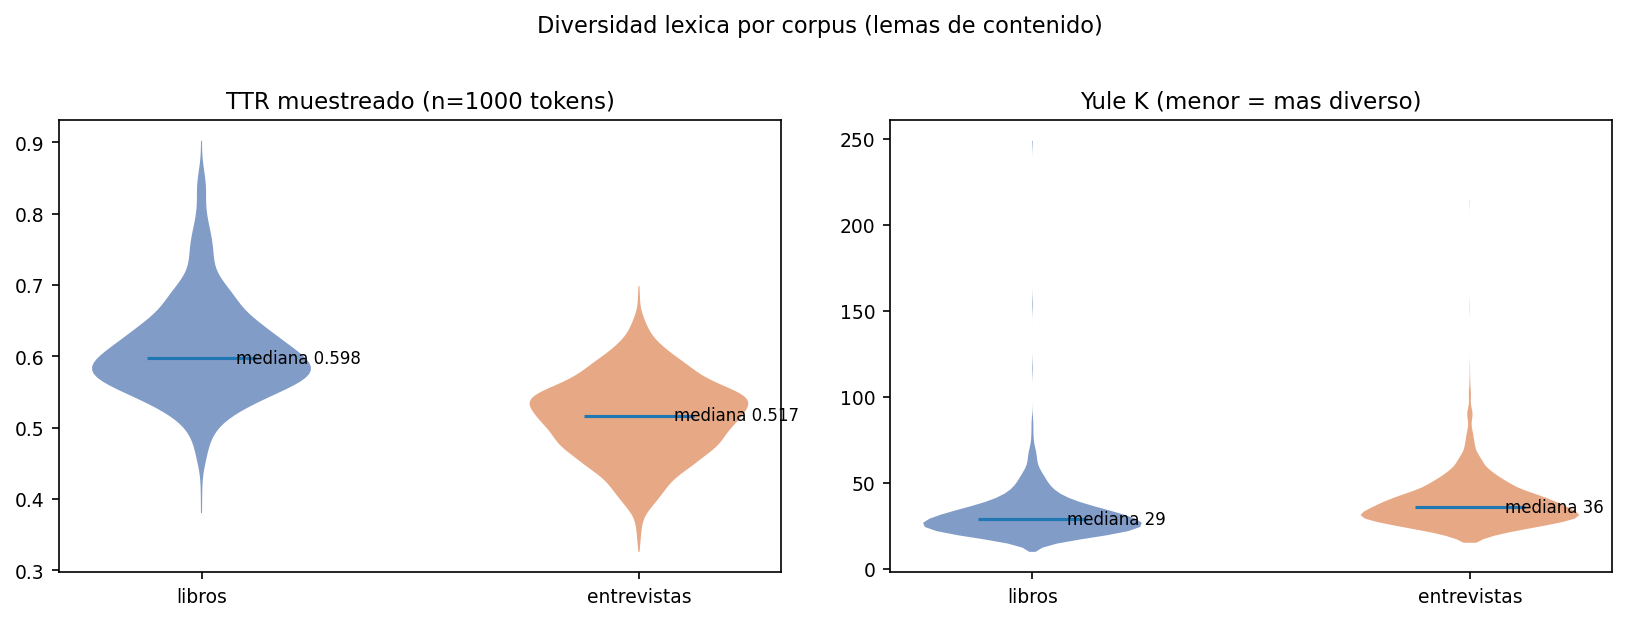

In [15]:
"""Dos figuras adicionales desde CSVs baratos de resultados/eda/."""

longitudes = pd.read_csv(RUTA_EDA_RESULTADOS / "longitudes_por_doc.csv")
diversidad = pd.read_csv(RUTA_EDA_RESULTADOS / "diversidad_lexica.csv")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, corpus, color in zip(
    ejes, ("libros", "entrevistas"), ("#4C72B0", "#DD8452"), strict=True
):
    sub = longitudes[longitudes["corpus"] == corpus]["n_lemas_contenido_eda"]
    ax.hist(sub, bins=60, color=color, edgecolor="white")
    ax.set_title(
        f"{corpus}: lemas de contenido (EDA)\nn={len(sub)} "
        f"media={sub.mean():,.0f} mediana={sub.median():,.0f}",
        fontsize=10,
    )
    ax.set_xlabel("lemas de contenido por documento")
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica, titulo, formato in [
    (ejes[0], "ttr_m1000", "TTR muestreado (n=1000 tokens)", ".3f"),
    (ejes[1], "yule_k", "Yule K (menor = mas diverso)", ".0f"),
]:
    datos = [
        diversidad.loc[diversidad["corpus"] == c, metrica].dropna().to_numpy()
        for c in ("libros", "entrevistas")
    ]
    violines = ax.violinplot(datos, showmedians=True, showextrema=False)
    for cuerpo, color in zip(
        violines["bodies"], ["#4C72B0", "#DD8452"], strict=True
    ):
        cuerpo.set_facecolor(color)
        cuerpo.set_alpha(0.7)
    ax.set_xticks([1, 2], ("libros", "entrevistas"))
    ax.set_title(titulo)
    for pos, arr in enumerate(datos, start=1):
        ax.text(
            pos + 0.08,
            float(np.median(arr)),
            f"mediana {np.median(arr):{formato}}",
            va="center",
            fontsize=8,
        )
fig.suptitle("Diversidad lexica por corpus (lemas de contenido)", y=1.02)
fig.tight_layout()
plt.show()

## Figuras pesadas del EDA (Fase 5) — I. Estadisticas y longitudes

Figuras generadas por scripts/03_eda.py y embebidas desde `../imagenes/`
(ruta relativa al notebook, que vive en `notebooks/`).

### Longitudes de los documentos

**Figura 1 — Libros: histograma de lemas de contenido por segmento**

![Histograma de lemas por segmento de libro](../imagenes/eda_libros_hist_lemas.png)

Distribucion compacta y acotada (la banda 300-4.000 palabras del ADR-001 se
nota en el rango 117-1.765 lemas): media 1.012 y mediana 1.124 lemas por
segmento; los histogramas de la Fase 5 usan los lemas de contenido (post
parada), por eso la media difiere de la de la seccion anterior (salida cruda
de la fase 4).

**Figura 2 — Libros: lemas de contenido por segmento y tomo**

![Boxplot de lemas por tomo](../imagenes/eda_libros_lemas_por_tomo.png)

VIOLACIONES (1.317) y ETNICO (1.357) tienen los segmentos mas largos en media,
y CONVOCATORIA los mas cortos (420): el tamano del segmento varia con el
genero del capitulo (informe analitico vs recopilacion de casos).

**Figura 3 — Entrevistas: histograma de lemas de contenido**

![Histograma de lemas por entrevista](../imagenes/eda_entrevistas_hist_lemas.png)

Asimetria extrema tipica de la oralidad: media 3.903 lemas pero mediana 3.113
y cola hasta 45.278 (p99 = 20.282, recorte visual): hay pocas entrevistas
muy largas y muchas de tamano medio.

**Figura 4 — Entrevistas: histograma de caracteres normalizados**

![Histograma de caracteres por entrevista](../imagenes/eda_entrevistas_hist_chars.png)

El texto normalizado va de 0 a 824.072 caracteres; las 2 entrevistas vacias
legitimas (sin texto de origen) se conservan y se documentan en
`resultados/eda/longitudes_por_doc.csv`.

**Figura 5 — Entrevistas: histograma de paginas por entrevista**

![Histograma de paginas por entrevista](../imagenes/eda_entrevistas_hist_paginas.png)

Las transcripciones van de 1 a 204 paginas (el PDF original conserva el
conteo de paginas escaneadas); la mayoria de entrevistas se concentra por
debajo de 30 paginas.

## II. Diversidad lexica

**Figura 6 — Violines de TTR muestreado y Yule K por corpus**

![Diversidad lexica por corpus](../imagenes/eda_diversidad_lexica.png)

Paneles de violin por documento: TTR con muestra fija n=1.000 (Bestgen,
2023): media 0,609 en libros vs 0,514 en entrevistas; Yule K 31,8 vs 38,7
(menor = mas diverso). La oralidad transcrita es sistematicamente mas
repetitiva, ruido conocido del registro hablado (Moreno-Sandoval, 2024).

## III. Nubes uni/bi/trigramas (lemas de contenido, top-150)

**Figuras 7-9 — Libros: nubes de unigramas, bigramas y trigramas**

![Nube de unigramas de libros](../imagenes/eda_libros_nube_unigramas.png)

Unigramas de libros: armado, victima, grupo, persona, violencia, comision:
lexico del informe analitico sobre el conflicto.

![Nube de bigramas de libros](../imagenes/eda_libros_nube_bigramas.png)

Bigramas de libros: conflicto armado, derechos humanos, grupo armado,
fuerza publica: colocaciones de dominio estables (por eso el modelo IR usa
ngram_range=(1,2), ADR-005).

![Nube de trigramas de libros](../imagenes/eda_libros_nube_trigramas.png)

Trigramas de libros: violacion de derechos humanos, nina nino adolescente:
colocaciones mas largas, dispersas (el EDA no encontro trigramas estables y
por eso no entran al vectorizador).

**Figuras 10-12 — Entrevistas: nubes de unigramas, bigramas y trigramas**

![Nube de unigramas de entrevistas](../imagenes/eda_entrevistas_nube_unigramas.png)

Unigramas de entrevistas: gente, llegar, ano, pasar, cosa, venir, querer:
verbos y sustantivos de la narracion oral de vida, no del informe.

![Nube de bigramas de entrevistas](../imagenes/eda_entrevistas_nube_bigramas.png)

Bigramas de entrevistas: ano_ano y conocido_conocido (reduplicaciones orales)
y grupo_armado / conflicto_armado: el lexico de dominio aparece, pero
contaminado por la repeticion del habla.

![Nube de trigramas de entrevistas](../imagenes/eda_entrevistas_nube_trigramas.png)

Trigramas de entrevistas: conocido_conocido_conocido, junta_accion_comunal y
unidad_militar_ejercito (categorias de anonimizacion pegadas al contexto).

## IV. Comparacion lexica y near-duplicates

**Figura 13 — Terminos distintivos libros vs entrevistas (log-odds)**

![Distintivos por log-odds](../imagenes/eda_comparacion_distintivos_logodds.png)

Log-odds con previo de Dirichlet 0,5: los distintivos de libros son tecnicos
(transmedia 8,0, externas 7,8, microdato 7,4) y los de entrevistas son las
categorias de anonimizacion (anonimo 9,1, organizacion_social 8,5,
organizacion_publica 8,2): huella del registro oral y de la normalizacion,
no del contenido. El solapamiento Jaccard de vocabulario es solo 0,221
(25.851 tipos compartidos), pero el vocabulario de libros cubre el 95,7 % de
los tokens de entrevistas.

**Figura 14 — Near-duplicates entre entrevistas**

![Near duplicates de entrevistas](../imagenes/eda_near_duplicates_entrevistas.png)

Izquierda: histograma de Jaccard (shingles de 5 lemas) de los 368 pares
candidatos LSH, con la linea del umbral 0,85; derecha: top-10 pares casi
identicos. Hay 345 pares > 0,85 (526 entrevistas unicas, 21,2 % del corpus)
y se REPORTAN sin eliminar: el corpus oficial debe permanecer integro, y el
matching IR ya los trata como documentos separados.

## V. Metricas por fase del proyecto (resultados/metricas.json)

Resumen acumulativo del proyecto por fase (fuente:
`resultados/metricas.json`, Fases 3 a 6):

| Fase | Script | Alcance | Resultado clave |
|---|---|---|---|
| 3 | `scripts/01_extraer_libros.py` | Extraccion de los 10 tomos PDF | 917 segmentos / 2.271.493 palabras; mapeo TOC 91-100 %, cobertura 100 %, 0 solapes |
| 4 | `scripts/02_preprocesar.py` | Normalizacion + spaCy (2.486 entrevistas) | 200,5M -> 188,8M chars (-5,8 %); 197.630 anonimizados a 8 categorias; 40,3M tokens -> 10,9M lemas (27,1 %) |
| 5 | `scripts/03_eda.py` | EDA y congelacion de config | TTR 0,609/0,514; Yule K 31,8/38,7; Jaccard 0,221; 345 near-dups; config tf-idf congelada |
| 6 | `experimentos/experimento_1_tfidf_base.py` + `scripts/04_evaluar_muestra.py` | IR TF-IDF + evaluacion de muestra | 118.748 features; 2.484/2.486 queries con match; P@1 estricto 0,533 / aceptable 1,0 (muestra 30) |

La Fase 6 se ejecuta y discute en la seccion siguiente (Sec 03).

# Sec 03 — Recuperacion de Informacion: experimento TF-IDF base

Se ejecuta aqui el **experimento IR base** de la Fase 6 importando el modulo
de produccion `experimentos/experimento_1_tfidf_base.py` (importlib con
sys.path hacia experimentos/, sin duplicar su logica). El modulo expone el
pipeline en funciones puras (`cargar_lemas_y_metadatos`, `correr_variante`),
de modo que el notebook corre el modelo en memoria SIN sobrescribir los
resultados oficiales de `resultados/` (los CSVs del experimento quedan
intactos).

Direccion de matching (ADR-005): cada entrevista (2.486) es una query y la
coleccion son los 917 segmentos de libro. TF-IDF con saturacion de tf
(sublinear_tf), norma l2 y ngram_range=(1,2), config congelada en
config/tfidf_config.json (min_df=2, max_df=0,85); parada en consumo
(spacy STOP_WORDS + 51 muletillas + 42 ruido) y 62 correcciones de lemas.
Similitud coseno por batches y ranking top-5 por query.

La celda imprime el ranking top-5 (5 filas) y el contexto del experimento
(features, densidad, queries vacias). La corrida tarda ~10 s.

In [16]:
"""Carga del modulo del experimento y corrida del pipeline base (en memoria)."""
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "RUTA_RAIZ" not in globals():  # respaldo standalone (ver sec00_setup)
    import os as _os

    _candidato = Path(_os.getcwd()).resolve()
    while _candidato != _candidato.parent:
        if (_candidato / "data" / "corpus" / "segmentos_libros.jsonl").exists():
            break
        _candidato = _candidato.parent
    RUTA_RAIZ = _candidato
    RUTA_EXPERIMENTOS = RUTA_RAIZ / "experimentos"
    RUTA_RESULTADOS = RUTA_RAIZ / "resultados"

if "cargar_modulo_ir" not in globals():  # respaldo standalone (igual logica)
    import importlib
    import sys

    def cargar_modulo_ir():
        if "experimento_1_tfidf_base" in sys.modules:
            return sys.modules["experimento_1_tfidf_base"]
        sys.path.insert(0, str(RUTA_EXPERIMENTOS))
        return importlib.import_module("experimento_1_tfidf_base")

exp = cargar_modulo_ir()

# ===== Pipeline base completo (en memoria; no escribe archivos) =====
lineas_libros, docs_libros = exp.cargar_lemas_y_metadatos("libros")
lineas_entrevistas, docs_entrevistas = exp.cargar_lemas_y_metadatos("entrevistas")
contexto = exp.correr_variante(
    "base", lineas_libros, docs_libros, lineas_entrevistas, docs_entrevistas
)
ranking_top5 = contexto["ranking_top5"]

print(f"\nRanking top-5 generado en memoria: {len(ranking_top5)} filas "
      f"({ranking_top5['id_doc'].nunique()} queries)")
print("\nHead del ranking (primeras 5 filas = top-5 de la primera query):")
print(ranking_top5.head(5).to_string(index=False))


[experimento base] ngram=(1, 2) | parada=611 tokens | correcciones=62


  lemas coleccion: 923912 -> docs limpios 917/917
  lemas queries: 9702400 -> queries no vacias 2484/2486 | vacias tras parada: 2


  fit coleccion: (917, 118748) | transform queries: (2486, 118748)
  vocabulario: 118748 features (18864 unigramas + 99884 bigramas) | densidad tf coleccion: 0.008190


  ranking top-5: 12420 filas | head:
                      id_doc  rango                                                                  id_segmento    score        tomo                                                  titulo_segmento
5eb4e7bfda6da3b502da3589.pdf      1 SUFRIR-p253-los-obstaculos-a-la-participacion-electoral-y-al-derecho-al-voto 0.160936      SUFRIR Los obstáculos a la participación electoral y al derecho al voto
5eb4e7bfda6da3b502da3589.pdf      2                        NARRATIVA-p213-25-el-genocidio-de-la-union-patriotica 0.155458   NARRATIVA                          25. El genocidio de la Unión Patriótica
5eb4e7bfda6da3b502da3589.pdf      3                 VIOLACIONES-p701-esta-guerra-esta-viva-por-que-sigue-pasando 0.154993 VIOLACIONES                    Esta guerra está viva ¿Por qué sigue pasando?
5eb4e7bfda6da3b502da3589.pdf      4                 VIOLACIONES-p708-esta-guerra-esta-viva-por-que-sigue-pasando 0.136176 VIOLACIONES                    Esta guerra es


Ranking top-5 generado en memoria: 12420 filas (2484 queries)

Head del ranking (primeras 5 filas = top-5 de la primera query):
                      id_doc  rango                                                                  id_segmento    score        tomo                                                  titulo_segmento
5eb4e7bfda6da3b502da3589.pdf      1 SUFRIR-p253-los-obstaculos-a-la-participacion-electoral-y-al-derecho-al-voto 0.160936      SUFRIR Los obstáculos a la participación electoral y al derecho al voto
5eb4e7bfda6da3b502da3589.pdf      2                        NARRATIVA-p213-25-el-genocidio-de-la-union-patriotica 0.155458   NARRATIVA                          25. El genocidio de la Unión Patriótica
5eb4e7bfda6da3b502da3589.pdf      3                 VIOLACIONES-p701-esta-guerra-esta-viva-por-que-sigue-pasando 0.154993 VIOLACIONES                    Esta guerra está viva ¿Por qué sigue pasando?
5eb4e7bfda6da3b502da3589.pdf      4                 VIOLACIONES-p708-esta-g

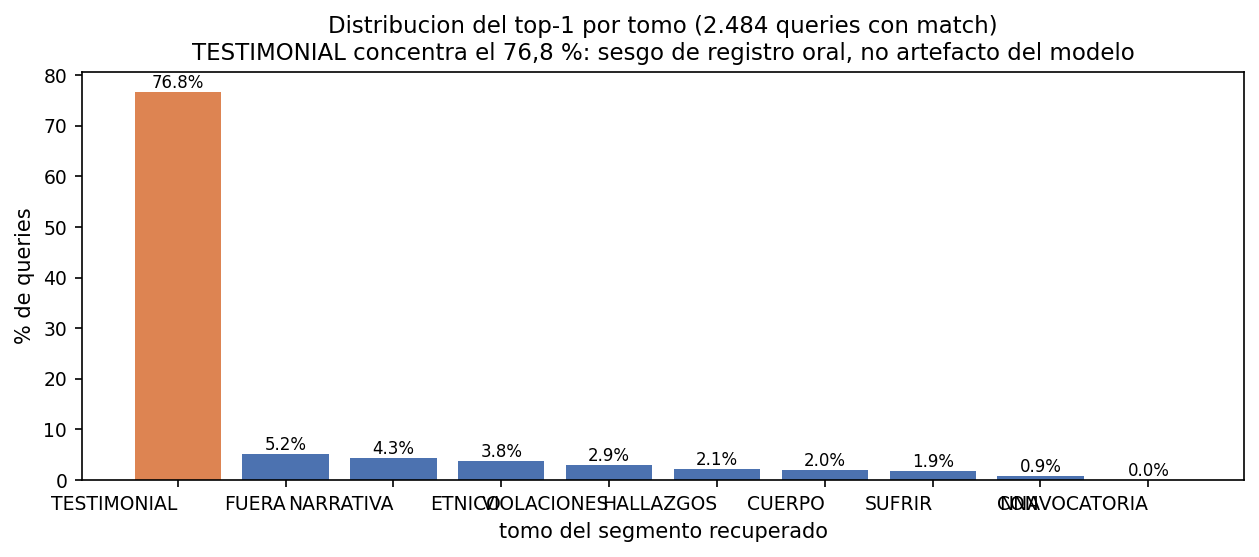

Score top-1: media = 0.146813 | mediana = 0.138242
Verificacion vs ranking_top5.csv: top-1 identicos en 2484/2484 queries | TESTIMONIAL: 76.77 % (memoria) = 76.77 % (CSV oficial) -> reproducido: True


In [17]:
"""Top-1 por tomo, score medio/mediana y verificacion contra el CSV oficial."""

top1 = ranking_top5[ranking_top5["rango"] == 1].copy()
distribucion = top1["tomo"].value_counts()
porcentajes = 100.0 * distribucion / len(top1)

fig, ax = plt.subplots(figsize=(10, 4))
colores = ["#DD8452" if tomo == "TESTIMONIAL" else "#4C72B0" for tomo in distribucion.index]
barras = ax.bar(distribucion.index, porcentajes, color=colores)
ax.bar_label(barras, fmt="%.1f%%", fontsize=8)
ax.set_title(
    "Distribucion del top-1 por tomo (2.484 queries con match)\n"
    "TESTIMONIAL concentra el 76,8 %: sesgo de registro oral, no artefacto del modelo"
)
ax.set_xlabel("tomo del segmento recuperado")
ax.set_ylabel("% de queries")
fig.autofmt_xdate(rotation=0)
plt.show()

print(f"Score top-1: media = {top1['score'].mean():.6f} | "
      f"mediana = {top1['score'].median():.6f}")

# Verificacion: el ranking en memoria debe ser identico al CSV oficial
# resultados/ranking_top5.csv (mismo codigo y config; corrida determinista).
base_csv = pd.read_csv(RUTA_RESULTADOS / "ranking_top5.csv")
top1_csv = base_csv[base_csv["rango"] == 1].set_index("id_doc")["id_segmento"]
top1_mem = top1.set_index("id_doc")["id_segmento"]
n_coinciden = int((top1_csv == top1_mem).sum())
pct_csv = 100.0 * (base_csv[base_csv["rango"] == 1]["tomo"] == "TESTIMONIAL").mean()
pct_mem = 100.0 * (top1["tomo"] == "TESTIMONIAL").mean()
print(
    f"Verificacion vs ranking_top5.csv: top-1 identicos en {n_coinciden}/"
    f"{len(top1_mem)} queries | TESTIMONIAL: {pct_mem:.2f} % (memoria) = "
    f"{pct_csv:.2f} % (CSV oficial) -> reproducido: {n_coinciden == len(top1_mem)}"
)

In [18]:
"""Variantes A/B/C: coincidencia del top-1 con el base (desde CSVs)."""

# A: ngram (1,1); B: sin muletillas; C: sin correcciones de lemas.
base_top1 = pd.read_csv(RUTA_RESULTADOS / "ranking_top5.csv")
base_top1 = base_top1[base_top1["rango"] == 1].set_index("id_doc")["id_segmento"]
esperado = {"A": 54.8, "B": 84.6, "C": 96.6}
filas_variantes = []
for nombre, pct_esperado in esperado.items():
    variante = pd.read_csv(RUTA_RESULTADOS / f"ranking_top5_{nombre}.csv")
    top1_variante = variante[variante["rango"] == 1].set_index("id_doc")["id_segmento"]
    comun = base_top1.index.intersection(top1_variante.index)
    coincidencia = 100.0 * (base_top1[comun] == top1_variante[comun]).mean()
    filas_variantes.append(
        {
            "variante": nombre,
            "cambio_respecto_base": {
                "A": "sin bigramas (ngram 1,1)",
                "B": "sin parada de muletillas",
                "C": "sin correcciones de lemas",
            }[nombre],
            "coincidencia_top1_pct": round(coincidencia, 1),
            "esperado_reporte_pct": pct_esperado,
        }
    )
tabla_variantes = pd.DataFrame(filas_variantes)
print("Coincidencia del top-1 de cada variante con el base (2.484 queries):")
print(tabla_variantes.to_string(index=False))
ok = np.allclose(
    tabla_variantes["coincidencia_top1_pct"],
    tabla_variantes["esperado_reporte_pct"],
    atol=0.05,
)
print(f"Reproduce los valores del reporte (A 54,8 / B 84,6 / C 96,6): {ok}")
print(
    "Lectura: el bigrama aporta el 45 % del cambio de top-1; las muletillas "
    "mueven poco (15 %); las 62 correcciones casi nada (3 %). La config base "
    "es la mas estable."
)

Coincidencia del top-1 de cada variante con el base (2.484 queries):
variante      cambio_respecto_base  coincidencia_top1_pct  esperado_reporte_pct
       A  sin bigramas (ngram 1,1)                   54.8                  54.8
       B  sin parada de muletillas                   84.6                  84.6
       C sin correcciones de lemas                   96.6                  96.6
Reproduce los valores del reporte (A 54,8 / B 84,6 / C 96,6): True
Lectura: el bigrama aporta el 45 % del cambio de top-1; las muletillas mueven poco (15 %); las 62 correcciones casi nada (3 %). La config base es la mas estable.


In [19]:
"""Tabla de evaluacion etiquetada (30 pares) y metricas proxy."""

evaluacion = pd.read_csv(RUTA_RESULTADOS / "evaluacion_muestra_etiquetada.csv")
print(f"Muestra etiquetada: {len(evaluacion)} pares query -> segmento top-1\n")

tabla_eval = evaluacion[
    ["id_doc", "r1_tomo", "r1_score", "etiqueta"]
].copy()
tabla_eval["id_doc"] = tabla_eval["id_doc"].str[:20] + ".."
tabla_eval["r1_score"] = tabla_eval["r1_score"].round(4)
print("Las 30 filas etiquetadas (id truncado; r1 = segmento top-1):")
print(tabla_eval.to_string(index=False))

conteo = evaluacion["etiqueta"].value_counts()
print("\nConteo de etiquetas:", dict(conteo))

metricas_eval = json.loads(
    (RUTA_RESULTADOS / "evaluacion_metricas.json").read_text(encoding="utf-8")
)
print("\nMetricas proxy sobre la muestra (etiquetado humano-proxy):")
print(f"  P@1 estricto (solo 'relacionado')         : "
      f"{metricas_eval['p1_proxy']['estricto_solo_relacionado']:.4f}")
print(f"  P@1 aceptable ('relacionado' o 'parcial') : "
      f"{metricas_eval['p1_proxy']['aceptable_relacionado_o_parcial']:.4f}")
print(f"  P@3 aceptable (>=1 'relacionado')         : "
      f"{metricas_eval['p3_proxy']['aceptable_al_menos_un_relacionado']:.4f}")
print(f"  Top-1 'parcial' con match 'relacionado' en r2-r3: "
      f"{metricas_eval['errores_top1']['n_top1_parcial_con_match_relacionado_r2_r3']}/30")
sesgo = metricas_eval["sesgo_testimonial"]
print(f"  En la muestra, top-1 TESTIMONIAL: {sesgo['n_top1_testimonial_en_muestra']} "
      f"({dict(sesgo['distribucion_top1_testimonial'])})")

Muestra etiquetada: 30 pares query -> segmento top-1

Las 30 filas etiquetadas (id truncado; r1 = segmento top-1):
                id_doc      r1_tomo  r1_score    etiqueta
5f6ae4b606158f011ed0..    HALLAZGOS    0.1344 relacionado
5eb4eb12da6da3b502db..    HALLAZGOS    0.1319 relacionado
5fee58599e8b013f2692..    HALLAZGOS    0.1268 relacionado
5eb4e860da6da3b502da.. CONVOCATORIA    0.1549     parcial
5eb4eb13da6da3b502db..    NARRATIVA    0.1643     parcial
5eb4e9fbda6da3b502da..    NARRATIVA    0.1581     parcial
5ef8d0a8f1cdbf68d095..    NARRATIVA    0.1482 relacionado
5eb4e861da6da3b502da..       SUFRIR    0.1478 relacionado
5faa8396205391c03b5f..       SUFRIR    0.1751 relacionado
625fd7b8755cba02e5b6..       SUFRIR    0.1086     parcial
5f09f4e4f1cdbf68d05d..  TESTIMONIAL    0.1379     parcial
5eb4eb43da6da3b502db..  TESTIMONIAL    0.1146     parcial
5f040d37f1cdbf68d015..  TESTIMONIAL    0.1335 relacionado
5ececeaf215810782986..       CUERPO    0.1180 relacionado
603bab289e8b013

## Ejemplos curados de top-1 (seleccion de evaluacion_muestra_etiquetada.csv)

Cinco pares query (entrevista) -> top-1 (segmento de libro) seleccionados de
`resultados/evaluacion_muestra_etiquetada.csv` (etiquetado humano-proxy con
contexto ampliado del corpus): 2 relacionados buenos, 2 parciales y 1 caso
borde (el mas cercano a un falso positivo duro de la muestra).

**1. Relacionado bueno — el segmento abre con el mismo tipo de testimonio**
- id_doc: `5eb4eb12da6da3b502db359f.pdf` | id_segmento:
  `HALLAZGOS-p129-las-masacres` (HALLAZGOS) | score: 0,1319
- Por que: la entrevista narra una amenaza de masacre a una comunidad
  campesina (actores armados, plazo para salir, asesinato de un companero) y
  el segmento "Las masacres" abre con ese mismo tipo de relato: match
  genuino de hecho y poblacion.

**2. Relacionado bueno — caso etnico especifico bien recuperado**
- id_doc: `5fee5bef9e8b013f26931324.pdf` | id_segmento:
  `ETNICO-p448-violencias-danos-y-resistencias-de-los-pueblos-etnicos-en-el-conflicto-armado`
  (ETNICO) | score: 0,1235
- Por que: lider raizal sobre el impacto del conflicto y la discriminacion
  racial en San Andres; el segmento cita el caso raizal. Recupera la
  poblacion etnica correcta y su afectacion, no un segmento generico.

**3. Parcial — solape de tema amplio, desviacion del hecho concreto**
- id_doc: `5eb4eb13da6da3b502db35e7.pdf` | id_segmento:
  `NARRATIVA-p547-86-negociar-como-si-no-hubiera-guerra-y-pelear-como-si-no-hubiera-negociacion`
  (NARRATIVA) | score: 0,1643 (el mas alto de los ejemplos)
- Por que: la query es de un analista de relaciones internacionales sobre
  asistencia militar de EE. UU. (Plan Colombia, Guerra Fria) y el top-1
  trata la negociacion de La Habana: ambos son "guerra y salidas del
  conflicto", pero el match especifico no aparece en el top-3.

**4. Parcial — caso representativo del sesgo de especificidad**
- id_doc: `5ef4e445f1cdbf68d06e9f17.pdf` | id_segmento:
  `FUERA-p99-de-la-guerra-total-a-la-paz-incompleta-2006-2016` (FUERA) |
  score: 0,1623
- Por que: joven que socializo los acuerdos de paz y salio del pais; el
  top-1 es la historia macro 2006-2016. Coincide la epoca ("paz
  incompleta") pero no su vivencia del exilio: ilustra el fenomeno de 7/30
  queries con top-1 parcial y mejor match en r2-r3.

**5. Caso borde — top-1 TESTIMONIAL por solape de registro oral**
- id_doc: `5f148660f1cdbf68d0e27e16.pdf` | id_segmento:
  `TESTIMONIAL-p401-senderos-pedregosos` (TESTIMONIAL) | score: 0,1539
- Por que: mujer indigena amazonica excombatiente de las FARC; el top-1 es
  el testimonio oral de un joven nasa del Cauca. No comparten poblacion,
  region ni hecho: el ranking los emparejo por el registro oral compartido.
  Es el caso mas cercano a un falso positivo duro de la muestra (etiquetado
  `parcial` por prudencia).

Lectura general: el modelo recupera bien cuando la query tiene terminos de
dominio especificos (masacres, raizal), pero tiende a emparejar por solape
lexico general del conflicto y por registro oral cuando la entrevista es
testimonial.

## Discusion

**El sesgo TESTIMONIAL (76,77 % de top-1) es del dominio, no un artefacto
del modelo.** Con 2.484 queries con match, 1.907 (76,77 %) recuperan como
top-1 un segmento del tomo TESTIMONIAL. No se explica por el tamano del tomo
(104 de 917 segmentos, 11,3 %) ni por un defecto de TF-IDF: las entrevistas
son testimonios orales y el tomo TESTIMONIAL es el unico compilado de
testimonios; el solape lexico de registro (y el vocabulario comun del
conflicto) domina el ranking. La evaluacion cualitativa lo confirma: en la
muestra los 5 top-1 TESTIMONIAL son `relacionado` (2) o `parcial` (3) y
ninguno es `no`: el sesgo produce resultados plausibles, no falsos positivos
duros.

**7 de 30 queries (23 %) tienen top-1 parcial con un match relacionado en
r2-r3.** Es el fenomeno de especificidad: el primer resultado no es el mas
especifico porque los segmentos compiten por solape lexico amplio (todo el
corpus habla de guerra, victimas y territorio), no por el hecho o la
poblacion concreta. El problema no es el registro oral (las muletillas ya
estan en parada), sino la ausencia de discriminacion tematica fina.

**Decision de iteracion: no crear experimento 2.** Con el umbral del plan
(P@1 aceptable >= 0,6) el base cumple holgadamente (P@1 aceptable = 1,0;
estricto = 0,533; P@3 aceptable = 0,767). Un exp2 que ampliara la parada del
lexico coloquial no atacaria la causa diagnosticada (afectaria por igual a
todos los segmentos) y seria sobre-ingenieria para el punto 3 del taller; la
decision queda registrada en `resultados/ir_tfidf_report.json` y en
`resultados/metricas.json`.

# Sec 04 — Observaciones, limitaciones y mejoras futuras

## Limitaciones del trabajo

1. **No hay gold estandar.** La CEV no publica juicios de relevancia
   query->segmento; la evaluacion es una proxy: etiquetado humano-proxy de
   30 pares (con contexto ampliado del corpus) con etiquetas
   {relacionado, parcial, no}. Las metricas P@1/P@3 son indicativas y
   cargan el sesgo del etiquetador; ampliar la muestra o usar una segunda
   cohorte cambiaria los numeros.

2. **El lematizador spaCy (es_core_news_md) falla en formas de la oralidad**
   colombiana: voseo y preteritos irregulares sin lematizar (p. ej.
   'atrevieron' -> 'atreveir', 154 ocurrencias de 10,9 M de lemas). La
   solucion fueron 62 correcciones (config/lemas_correcciones.json)
   aplicadas EN CONSUMO, no sobre el corpus: el archivo *_lemas.txt queda
   intacto y cualquier consumo futuro debe reaplicarlas (como hace este
   notebook via `aplicar_parada()`).

3. **Near-duplicates de entrevistas documentados, no eliminados.** 345 pares
   con Jaccard de shingles(5) > 0,85 (526 entrevistas unicas, ~21 % del
   corpus) se reportan en resultados/eda/near_duplicates_entrevistas.csv
   pero se conservan por integridad del corpus oficial; el ranking puede
   devolver segmentos casi identicos para queries equivalentes.

4. **PII hablada y etica de datos con testimonios.** La normalizacion
   estructural mapea los anonimizados del transcriptor a 8 categorias
   canonicas (ADR-002), pero el intermedio
   `data/corpus/entrevistas_normalizadas.jsonl` conserva nombres y datos
   personales que el transcriptor dejo en claro (PII hablada): es un
   archivo de trabajo, no de distribucion. Los corpus finales
   (`data/corpus/preprocesado/*_lemas.txt` y `*_tokens.txt`) no contienen
   superficie PII (solo lemas y categorias). Los testimonios pertenecen a
   victimas de la CEV: el uso debe ser exclusivamente academico, sin
   re-identificacion ni publicacion de fragmentos atribuibles.

5. **Otras:** 2 entrevistas vacias legitimas (sin texto de origen) que
   quedan sin filas de ranking; TF-IDF es bag-of-words (ignora orden y
   sintaxis); ruido tipografico de los PDF (palabras partidas, 'ibid.',
   42 tokens) excluido en el EDA pero presente en los lemas si otro consumo
   no aplica la lista de config/tfidf_config.json.

## Mejoras futuras (incluyen los puntos 4 y 5 del taller)

1. **Punto 4 del taller: BM25 (Okapi) y Rocchio.** Sustituir o combinar el
   tf-idf con BM25 (ponderacion por longitud de documento) y evaluar
   relevance feedback de Rocchio sobre la muestra etiquetada como
   pseudo-relevancia; comparar P@1/P@3 proxy contra el base.

2. **Punto 5 del taller: heatmap tomo x tomo.** Visualizar la confusion
   entre el tomo real de la entrevista y el tomo del top-1 (los datos ya
   existen en resultados/ranking_top5.csv y la distribucion TESTIMONIAL
   del 76,77 % pide este analisis por tomo y por periodo).

3. **Embeddings multilingues** (SBERT/multilingual E5 o similares) para el
   matching semantico: atacaria el problema diagnosticado de especificidad
   (7/30 top-1 parciales con mejor match en r2-r3) mejor que ampliar la
   parada, porque discrimina por sentido y no solo por solape lexico.

4. **Enrutamiento por tomo**: un clasificador previo tomo-query (o un
   reranker por tomo) podria corregir el prior TESTIMONIAL cuando la query
   pide un hecho o poblacion especifica (masacres, raizal, exilio).

5. **Gold estandar externo**: etiquetado por expertos del dominio (o una
   segunda cohorte de estudiantes) sobre una muestra mayor, para pasar de
   metricas proxy a P@k con acuerdo inter-etiquetador (kappa).

# Sec 05 — Entregables y reproduccion del taller

## Entregables (rutas dentro de TALLER-4)

| Entregable | Ruta |
|---|---|
| Tomos PDF crudos (10 PDF + zip original) | `data/raw/books/`, `data/raw/books-*.zip` |
| Entrevistas crudas (2.486, JSON unico) | `data/raw/entrevistas_all_2023-03-21_14-24_05.json` |
| Corpus de libros: segmentos (917) y por tomo | `data/corpus/segmentos_libros.jsonl`, `data/corpus/segmentos/<TOMO>.jsonl` |
| Corpus de entrevistas normalizado | `data/corpus/entrevistas_normalizadas.jsonl` |
| Corpus preprocesado (lemas, tokens, metadatos) | `data/corpus/preprocesado/` (`libros_*` 917 docs, `entrevistas_*` 2.486 docs) |
| Config congelada del modelo | `config/` (`tfidf_config.json`, `stopwords_habla.txt`, `lemas_correcciones.json`) |
| Codigo de extraccion, preprocesado, EDA y evaluacion | `scripts/01_extraer_libros.py`, `02_preprocesar.py`, `03_eda.py`, `04_evaluar_muestra.py` |
| Modelo IR TF-IDF (base y variantes A/B/C) | `experimentos/experimento_1_tfidf_base.py` |
| Figuras del EDA (14) | `imagenes/eda_*.png` |
| Ranking, reportes, muestra etiquetada y metricas | `resultados/` (`ranking_top5*.csv`, `ir_tfidf_report.json`, `evaluacion_metricas.json`, `metricas.json`, `eda/`) |
| Codigo fuente de este notebook | `notebook_cells/sec00_setup.py` ... `sec05_entrega.py`, `scripts/ensamblar_notebook_t4.py` |
| Notebook entregable (ejecutado) | `notebooks/Taller_4_IR_CEV.ipynb` |
| Tests | `tests/` (`test_extraccion.py`, `test_preprocesado.py`, `test_ir_tfidf.py`) |

## Como reproducir

**Requisitos** (venv de Carlos, Python 3.14):

```bash
/home/carlos/venv/bin/pip install pandas scikit-learn spacy matplotlib seaborn wordcloud
/home/carlos/venv/bin/python -m spacy download es_core_news_md   # modelo de la Fase 4
```

- `poppler-utils` (binario `pdftotext`) solo se necesita para REGENERAR la
  extraccion de los libros desde los PDF (Fase 3); el corpus ya extraido no
  lo requiere.
- Para re-ejecutar este notebook se adicionan `nbformat` y `nbclient`
  (solo herramienta de ejecucion, no del pipeline).

**Pipeline completo, en orden** (desde `TALLER-4/`):

```bash
# Fase 3: extraccion y segmentacion de los 10 tomos (917 segmentos)
/home/carlos/venv/bin/python scripts/01_extraer_libros.py

# Fase 4: normalizacion estructural + spaCy (lematizacion; ~9 min, 8 hilos)
/home/carlos/venv/bin/python scripts/02_preprocesar.py

# Fase 5: EDA, figuras y congelacion de config/tfidf_config.json
/home/carlos/venv/bin/python scripts/03_eda.py

# Fase 6: experimento IR base (ranking_top5.csv y reportes)
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py
# Variantes comparativas (no tocan los archivos del base):
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante A
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante B
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante C

# Evaluacion de la muestra de 30 pares (etiquetado proxy + metricas P@1/P@3)
/home/carlos/venv/bin/python scripts/04_evaluar_muestra.py

# Tests (pipeline sintetico, sin corpus completo)
/home/carlos/venv/bin/python -m pytest tests/ -q
```

**Re-ejecucion de este notebook** (ensamblado de celdas + ejecucion):

```bash
/home/carlos/venv/bin/python scripts/ensamblar_notebook_t4.py
/home/carlos/venv/bin/python -m nbclient ...
```

La seccion 00 del notebook detecta la raiz del proyecto automaticamente
(`buscar_raiz()`), por lo que puede abrirse en Jupyter desde `notebooks/`,
desde la raiz de TALLER-4 o en Colab con la carpeta TALLER-4 completa
subida; las figuras del EDA embebidas se resuelven con la ruta relativa
`../imagenes/eda_*.png` respecto de `notebooks/`.